# 01 — Data Cleaning and Exploratory Analysis
**Goal:** understand the monthly lithium carbonate target and audit predictor coverage before modeling.

The target is the selected lithium carbonate price in CNY/metric tonne. Missing predictor values do not remove target observations. The target itself is never imputed.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path("../data/lithium_consolidated_monthly.csv")
TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42

df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").drop_duplicates("Month").set_index("Month").asfreq("MS")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

## 1. Dataset overview

In [2]:
print("Shape:", df.shape)
print("Date range:", df.index.min(), "to", df.index.max())
print("Target observations:", df[TARGET].notna().sum())
display(df[[TARGET]].describe().T)
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing rows"))

Shape: (209, 35)
Date range: 2009-06-01 00:00:00 to 2026-10-01 00:00:00
Target observations: 209


,count,mean,std,min,25%,50%,75%,max
Selected lithium carbonate price (CNY/t),209.0,103596.464115,107918.796632,30000.0,37000.0,68000.0,126000.0,540375.0


,Missing rows
China spot price volume (CSV),209
China LFP power battery sales (thousand kWh),155
"China, Lithium Iron Phosphate Power Battery Sales",154
China lithium-ion battery production (source units),150
LME lithium hydroxide price (USD/metric tonne),146
China industrial production index (prior year = 100),127
Japan lithium battery production (thousands),121
Japan lithium battery shipments (thousands),121
Japan lithium battery inventory (thousands),121
US CPI (1982–84 = 100),120


## 2. Target price history

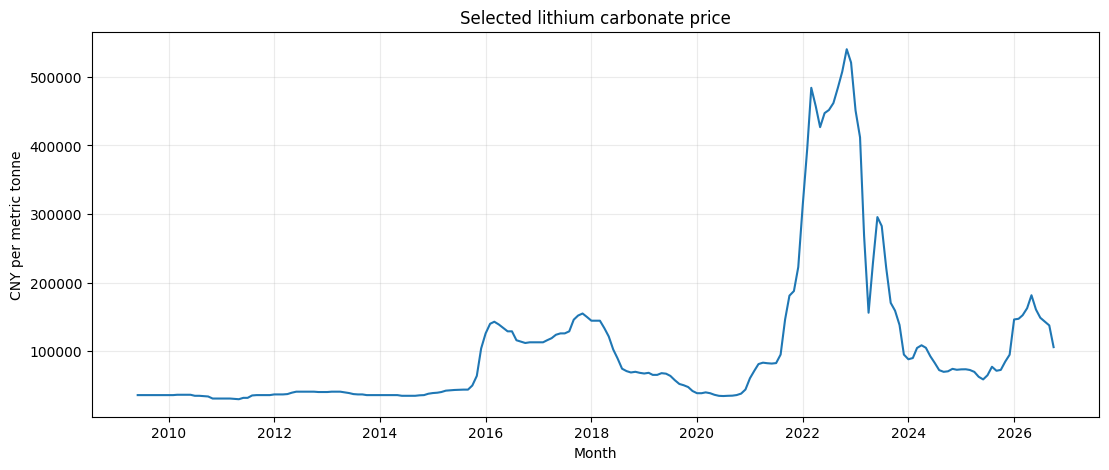

Target coverage: 2009-06 to 2026-10 (209 observations)


In [3]:
target = df[TARGET].dropna()
fig, ax = plt.subplots(figsize=(13,5))
ax.plot(target.index, target.values)
ax.set(title="Selected lithium carbonate price", xlabel="Month", ylabel="CNY per metric tonne")
ax.grid(alpha=.25)
plt.show()
print(f"Target coverage: {target.index.min():%Y-%m} to {target.index.max():%Y-%m} ({len(target)} observations)")

## 3. Predictor coverage audit

In [4]:
coverage = pd.DataFrame({
    "Non-missing": df.notna().sum(),
    "Missing": df.isna().sum(),
    "First available": [df[c].first_valid_index() for c in df.columns],
    "Last available": [df[c].last_valid_index() for c in df.columns],
})
coverage["Coverage (%)"] = (coverage["Non-missing"] / len(df) * 100).round(1)
display(coverage.sort_values("Coverage (%)", ascending=False))

,Non-missing,Missing,First available,Last available,Coverage (%)
Selected lithium carbonate price (CNY/t),209,0,2009-06-01,2026-10-01,100.0
Selected target source,209,0,2009-06-01,2026-10-01,100.0
"Japan, Production - Lithium Batteries",207,2,2009-06-01,2026-08-01,99.0
"Japan, Shipments - Lithium Batteries",207,2,2009-06-01,2026-08-01,99.0
"Japan, Inventory - Lithium Batteries",207,2,2009-06-01,2026-08-01,99.0
"Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100",201,8,2010-01-01,2026-09-01,96.2
LME cobalt cash price (USD/metric tonne) - updated Datastream,197,12,2010-06-01,2026-10-01,94.3
China spot price change (%) - CSV,186,23,2009-06-01,2024-11-01,89.0
China spot lithium carbonate price (CNY/t) - CSV,186,23,2009-06-01,2024-11-01,89.0
China spot price open (CNY/t) - CSV,186,23,2009-06-01,2024-11-01,89.0


## 4. Japan lithium carbonate import-price index

The Japan series in this dataset is an **import-price index (2020 = 100), yen basis**, not a directly quoted spot price in CNY/tonne or USD/tonne. It begins in January 2010 in this file. It can be tested as a lagged explanatory variable, but it should not replace the target series.

Japan import-price index observations: 201
Coverage: 2010-01-01 00:00:00 to 2026-09-01 00:00:00


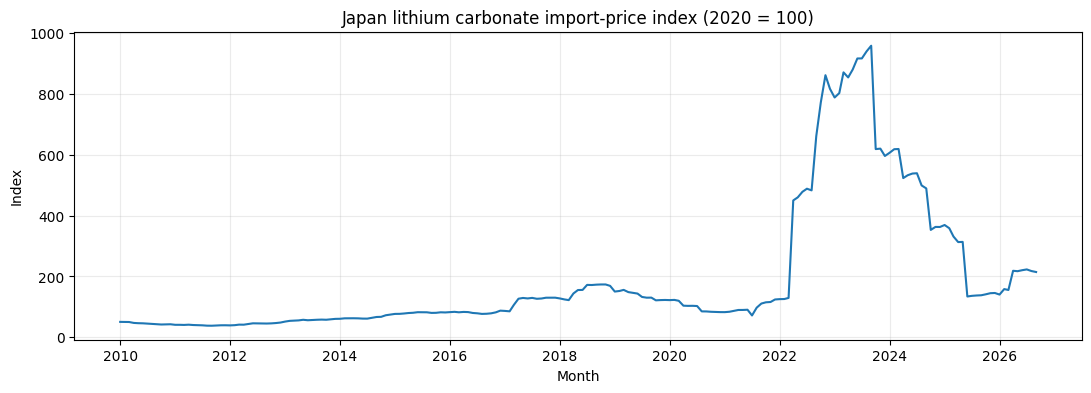

In [5]:
if JAPAN_INDEX in df.columns:
    s = pd.to_numeric(df[JAPAN_INDEX], errors="coerce").dropna()
    print("Japan import-price index observations:", len(s))
    print("Coverage:", s.index.min(), "to", s.index.max())
    fig, ax = plt.subplots(figsize=(13,4))
    ax.plot(s.index, s.values)
    ax.set(title="Japan lithium carbonate import-price index (2020 = 100)", xlabel="Month", ylabel="Index")
    ax.grid(alpha=.25)
    plt.show()

## 5. Cleaning decisions

- Keep every month with a valid target observation.
- Exclude the old constant cobalt series marked faulty.
- Exclude same-month target aliases and same-month OHLC/change variables from predictors.
- Do not backfill leading missing predictor values from the future.
- For forecasting, use lagged predictors and train-fitted imputation inside a scikit-learn pipeline.
- Treat any source stitching in the selected target as a limitation to investigate.

In [6]:
# Candidate predictors: numerical columns only, with explicit leakage/quality exclusions.
excluded = {
    TARGET, "Selected target source",
    "Lithium carbonate price (CNY/metric tonne)",
    "China spot lithium carbonate price (CNY/t) - CSV",
    "OLD - faulty cobalt settlement series (constant; excluded)",
    "China spot price open (CNY/t) - CSV",
    "China spot price high (CNY/t) - CSV",
    "China spot price low (CNY/t) - CSV",
    "China spot price volume (CSV)",
    "China spot price change (%) - CSV",
}
candidate_predictors = [c for c in df.select_dtypes(include=np.number).columns if c not in excluded]
print("Candidate predictors:", len(candidate_predictors))
display(coverage.loc[[c for c in candidate_predictors if c in coverage.index]].sort_values("Coverage (%)", ascending=False))

Candidate predictors: 25


,Non-missing,Missing,First available,Last available,Coverage (%)
"Japan, Shipments - Lithium Batteries",207,2,2009-06-01,2026-08-01,99.0
"Japan, Production - Lithium Batteries",207,2,2009-06-01,2026-08-01,99.0
"Japan, Inventory - Lithium Batteries",207,2,2009-06-01,2026-08-01,99.0
"Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100",201,8,2010-01-01,2026-09-01,96.2
LME cobalt cash price (USD/metric tonne) - updated Datastream,197,12,2010-06-01,2026-10-01,94.3
"China, Lithium Ion Battery Production",165,44,2009-06-01,2025-03-01,78.9
"China, Pure Electric Vehicle Sales",117,92,2017-01-01,2026-10-01,56.0
SQM share price (USD/ADR),90,119,2019-05-01,2026-10-01,43.1
Albemarle share price (USD/share),90,119,2019-05-01,2026-10-01,43.1
LME copper price (USD/metric tonne),90,119,2019-05-01,2026-10-01,43.1


## 6. Save cleaned analysis table

In [7]:
# Save a copy with dates and original missing values preserved.
df.to_csv("../results/monthly_data_audited.csv")
print("Saved ../results/monthly_data_audited.csv")

Saved ../results/monthly_data_audited.csv
